# 5. How Jordan can improve

Four notebooks of evidence, and most of it is about what already happened. This
one is about what is left, and it is organised by **how much the data actually
supports doing something about it**:

1. **What is measurably broken** — one finding, quantified, with the margin it
   would have to come out of.
2. **What did not change** — five nulls, reported as nulls, because each closes
   off an explanation that would otherwise stay live.
3. **What has never been tried** — the route almost every improving nation takes,
   which Jordan has taken exactly once.
4. **What has never been tested** — the placebo, and a power calculation showing
   what it would take.
5. **What cannot be known from this data** — stated plainly rather than
   worked around.

🚨 **One thing this notebook will not do is tell Jordan how to play.** Nothing
here identifies a cause. Squad change, coaching change and scheduling all move
together across mid-2022, about 40 matches follow it, and no design available
separates them. What follows is a list of measured gaps and honest unknowns.

In [1]:
import sys, json
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "JordanData"))
import viz
viz.use_style()

OUT = ROOT / "outputs"
SQUAD = OUT / "squad"
START, CUT = pd.Timestamp("2015-01-01"), pd.Timestamp(viz.SPLIT)
rng = np.random.default_rng(41)

mt = pd.read_csv(SQUAD / "match_table.csv", parse_dates=["date"]).sort_values("date")
goals = pd.read_csv(SQUAD / "goals.csv", parse_dates=["date"])
ap = pd.read_csv(SQUAD / "appearances_combined.csv")
ja = ap[ap.squad_id == "3e22f0fa"].copy()
ja["Min"] = pd.to_numeric(ja.Min, errors="coerce")

mt = mt[mt.date >= START].copy()
goals = goals[goals.date >= START].copy()
for d in (mt, goals):
    d["era"] = np.where(d.date < CUT, "pre", "post")
# six-month blocks: matches inside a window share a squad, a manager and a set
# of opponents, so the block is the unit a bootstrap resamples (Kunsch 1989)
mt["blk"] = mt.date.dt.year * 2 + (mt.date.dt.month > 6)

# A scorer is a player id, never a name -- the same man is transliterated
# several ways across sources (notebook 01, section 6).
gj = goals.dropna(subset=["scorer_player_id"]).copy()
NAMES = ja.dropna(subset=["player_id"]).groupby("player_id").Player.agg(
    lambda s: s.mode().iloc[0])
BLOCKS = {e: [d for _, d in mt[mt.era == e].groupby("blk")] for e in ("pre", "post")}


def block_boot(fn, nb=2000, frame=None):
    """Resample six-month blocks within each era; return (observed, lo, hi)."""
    src = mt if frame is None else frame
    blocks = {e: [d for _, d in src[src.era == e].groupby("blk")]
              for e in ("pre", "post")}
    obs = fn(src[src.era == "post"]) - fn(src[src.era == "pre"])
    vals = []
    for _ in range(nb):
        s = {e: pd.concat([blocks[e][i] for i in
                           rng.integers(0, len(blocks[e]), len(blocks[e]))])
             for e in ("pre", "post")}
        v = fn(s["post"]) - fn(s["pre"])
        if np.isfinite(v):
            vals.append(v)
    return (obs, *np.percentile(vals, [2.5, 97.5]))

## 1. What is measurably broken

Notebook 04's one actionable finding: **from a level scoreline at the 75th
minute, the goals go one way.** Of the 25 goals after the 75th in the 36 matches
Jordan reached that point level, Jordan scored 6 and conceded 19 — a share of
**0.240, 95% [0.048, 0.419]** against a model-implied 0.539, stable in both eras.
Downstream of that, 0.72 points per match where the model expects about 1.2.

The question this notebook adds is: **against whom, and how much would it be
worth?** Notebook 02's calibration gives the frame. Fitting Jordan's actual
results against the model's expectation for each fixture, the post-2022 line
crosses zero at expected goal difference **−0.31** — Jordan breaks even against
opposition up to about a third of a goal stronger than itself, and loses beyond
that.

**Plotted:** every post-2022 fixture, arranged by how much stronger or weaker the
opponent was. The dashed line is Jordan's break-even point from notebook 02's
calibration fit. Bars left of it are the fixtures Jordan currently expects to
lose; the annotation gives what share of the current schedule that is, and how
far the line would have to move to cover them.

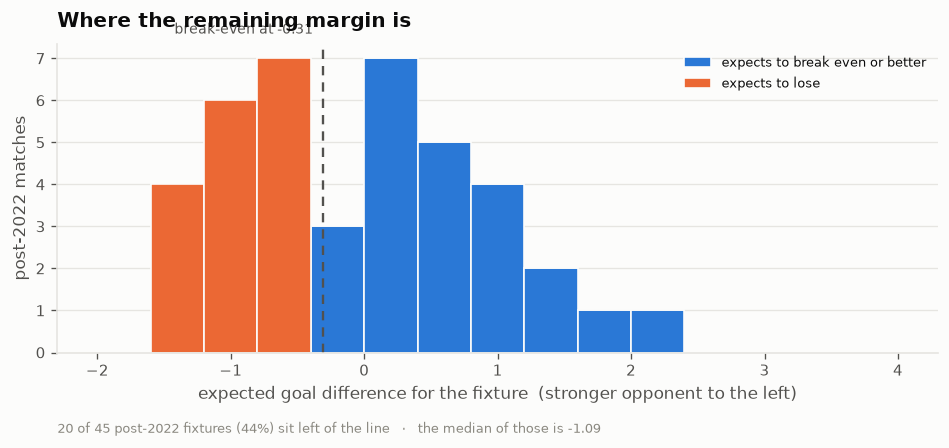

In [2]:
post = mt[mt.era == "post"].copy()
fit_post = np.polyfit(post.expected_gd, post.gd, 1)
BREAKEVEN = -fit_post[1] / fit_post[0]          # where the fitted line crosses 0
bins = np.arange(-2.0, 4.01, 0.4)

fig, ax = plt.subplots(figsize=(7.8, 3.6))
h_lose = post[post.expected_gd < BREAKEVEN].expected_gd
h_win = post[post.expected_gd >= BREAKEVEN].expected_gd
ax.hist([h_win, h_lose], bins=bins, stacked=True,
        color=[viz.BLUE, viz.ORANGE], edgecolor=viz.SURFACE, linewidth=1.0,
        label=["expects to break even or better", "expects to lose"])
ax.axvline(BREAKEVEN, color=viz.INK_2, lw=1.4, ls=(0, (4, 3)))
ax.annotate(f"break-even at {BREAKEVEN:+.2f}", xy=(BREAKEVEN, 1.0),
            xycoords=("data", "axes fraction"), xytext=(-6, 4),
            textcoords="offset points", ha="right", va="bottom", fontsize=8.5,
            color=viz.INK_2)
SHARE = (post.expected_gd < BREAKEVEN).mean()
ax.set_xlabel("expected goal difference for the fixture  "
              "(stronger opponent to the left)")
ax.set_ylabel("post-2022 matches")
ax.set_title("Where the remaining margin is")
ax.annotate(f"{int((post.expected_gd < BREAKEVEN).sum())} of {len(post)} "
            f"post-2022 fixtures ({SHARE:.0%}) sit left of the line   ·   "
            f"the median of those is {h_lose.median():+.2f}",
            xy=(0, -0.26), xycoords="axes fraction", fontsize=8,
            color=viz.INK_MUTED)
ax.legend(fontsize=8, loc="upper right")
viz.despine(ax)
ax.grid(axis="x", visible=False)
plt.show()

**That is the honest statement of the target.** Roughly **two in five** of
Jordan's current fixtures are against opposition it does not yet expect to hold,
and the typical one of those is about **a goal stronger**. Closing that is another rise of
the same size as the one 2015–2026 already delivered.

**And the level-scoreline finding is where the cheapest part of it sits.** About
**17 points** across those 36 matches, in fixtures the model already made Jordan
the favourite in. Those are not points against Argentina — they are points
against sides Jordan was level with, late, and expected to beat.

🚨 **Do not read a mechanism into it.** The obvious explanation — a team chasing
a winner and caught on the break — needs shot locations or possession to test,
and neither exists for these matches. Item 5 below.

## 2. What did not change

Each of these was built and returned nothing. They are reported because **a null
with an interval is a result**, and because each closes off an explanation that
would otherwise stay available to anyone telling the story afterwards.

In [3]:
ms = pd.read_csv(SQUAD / "match_state.csv", parse_dates=["date"])
ms = ms[(ms.date >= START) & ms.jordan_side.notna()].copy()
ms["era"] = np.where(ms.date < CUT, "pre", "post")
ms["blk"] = ms.date.dt.year * 2 + (ms.date.dt.month > 6)
# computed before the blocks are cut, or the bootstrap draws lack the column
ms["margin"] = ms.gf - ms.ga
SB = {e: [d for _, d in ms[ms.era == e].groupby("blk")] for e in ("pre", "post")}


def sboot(fn, nb_=1200):
    obs = fn(ms[ms.era == "post"]) - fn(ms[ms.era == "pre"])
    vals = []
    for _ in range(nb_):
        s = {e: pd.concat([SB[e][i] for i in rng.integers(0, len(SB[e]), len(SB[e]))])
             for e in ("pre", "post")}
        v = fn(s["post"]) - fn(s["pre"])
        if np.isfinite(v):
            vals.append(v)
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return obs, lo, hi


NULLS = [
    ("share of time leading", lambda d: (d.min_leading / d.match_end).mean()),
    ("share of time trailing", lambda d: (d.min_trailing / d.match_end).mean()),
    ("scores first", lambda d: d.first_goal.eq("for").mean()),
    ("trailed -> avoided defeat", lambda d: d.recovered.dropna().mean()),
    ("win by 3+", lambda d: (d.margin >= 3).mean()),
    ("lose by 3+", lambda d: (d.margin <= -3).mean()),
]
nulls = pd.DataFrame([dict(zip(("measure", "diff", "lo", "hi"),
                               (lab, *sboot(fn)))) for lab, fn in NULLS])


# Scoring rate per 90 minutes ACTUALLY SPENT in each state. Both numerator and
# denominator move when a match is resampled, so the rate is what is bootstrapped.
def srate(d, st, direction="gf"):
    m_ = d[f"min_{st}"].sum()
    return d[f"{direction}_{st}"].sum() / m_ * 90 if m_ > 0 else np.nan


srows = []
for st in ("leading", "level", "trailing"):
    o, lo, hi = sboot(lambda d, ss=st: srate(d, ss))
    srows.append({"measure": f"scoring rate, {st}", "diff": o, "lo": lo, "hi": hi,
                  "pre": srate(ms[ms.era == "pre"], st),
                  "post": srate(ms[ms.era == "post"], st)})


# the comparison of interest as one quantity: does the team push when behind?
def tratio(d):
    lv = srate(d, "level")
    return srate(d, "trailing") / lv if lv > 0 else np.nan


o, lo, hi = sboot(tratio)
srows.append({"measure": "trailing / level ratio", "diff": o, "lo": lo, "hi": hi})
state_nulls = pd.DataFrame(srows)
N_TRAIL = int(ms.gf_trailing.sum())

**Plotted:** post-2022 minus pre-2022 for each measure, with its block-bootstrap
interval. **Left:** measures that are shares of matches or of time. **Right:**
scoring rates per 90 minutes actually spent in each scoreboard state — a
different unit, so a different axis. Every interval crosses zero.

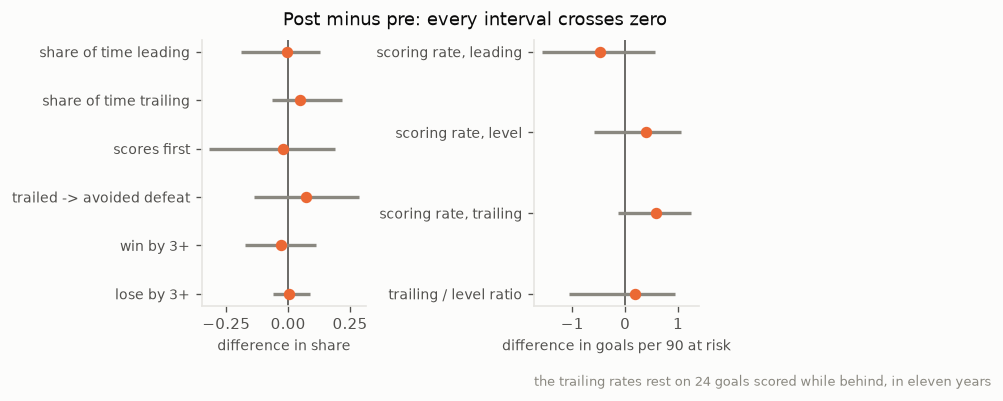

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.2))
for ax, tab, unit in ((axes[0], nulls, "difference in share"),
                      (axes[1], state_nulls, "difference in goals per 90 at risk")):
    d = tab.iloc[::-1].reset_index(drop=True)
    y = np.arange(len(d))
    ax.hlines(y, d.lo, d.hi, color=viz.INK_MUTED, lw=2.0)
    ax.scatter(d["diff"], y, color=viz.ORANGE, s=34, zorder=3)
    ax.axvline(0, color=viz.INK_2, lw=1.0, zorder=0)
    ax.set_yticks(y)
    ax.set_yticklabels(d.measure, fontsize=8.5)
    ax.set_xlabel(unit, fontsize=8.5)
    viz.despine(ax)
    ax.grid(axis="y", visible=False)
fig.suptitle("Post minus pre: every interval crosses zero", fontsize=11)
axes[1].annotate(f"the trailing rates rest on {N_TRAIL} goals scored while "
                 f"behind, in eleven years", xy=(0, -0.30),
                 xycoords="axes fraction", fontsize=8, color=viz.INK_MUTED)
plt.show()

**Plotted, left:** every goalkeeper with eight or more matches, and how those
matches split across the eras — a complete handover. **Middle:** each keeper's
mean goals conceded above the model's expectation, dot area tracking matches
played, because a 20-match mean should not read as loudly as a 53-match one.
**Right:** cards per match, by era.

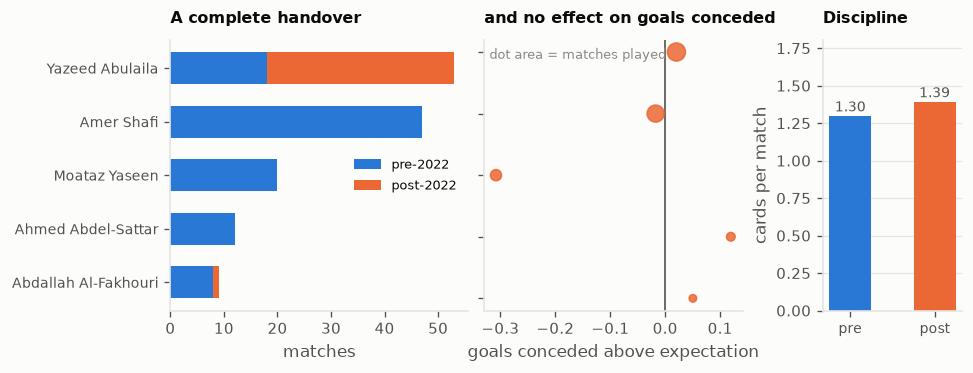

In [5]:
kp = pd.read_csv(SQUAD / "keeper.csv")
kj = kp[kp.squad_id == "3e22f0fa"].merge(
    mt[["match_id", "era", "date", "ga", "expected_ga"]], on="match_id")
kj["above"] = kj.ga - kj.expected_ga
k = (kj.groupby("Player").agg(matches=("match_id", "size"),
                              pre=("era", lambda s: (s == "pre").sum()),
                              post=("era", lambda s: (s == "post").sum()),
                              ga_above_expected=("above", "mean"))
     .sort_values("matches", ascending=False))
kk = k[k.matches >= 8].iloc[::-1]

fig, axes = plt.subplots(1, 3, figsize=(8.0, 3.0),
                         gridspec_kw={"width_ratios": [1.5, 1.3, 0.7]})
y = np.arange(len(kk))
a = axes[0]
a.barh(y, kk.pre, height=0.6, color=viz.BLUE, label="pre-2022")
a.barh(y, kk.post, left=kk.pre, height=0.6, color=viz.ORANGE, label="post-2022")
a.set_yticks(y)
a.set_yticklabels(kk.index, fontsize=8.5)
a.set_xlabel("matches")
a.set_title("A complete handover", fontsize=9.5)
a.legend(fontsize=8, loc="center right")
viz.despine(a)
a.grid(axis="y", visible=False)

b = axes[1]
b.scatter(kk.ga_above_expected, y, color=viz.ORANGE, zorder=3,
          s=kk.matches.values * 2.2, alpha=0.85)
b.axvline(0, color=viz.INK_2, lw=1.0)
b.set_yticks(y)
b.set_yticklabels([])
b.set_xlabel("goals conceded above expectation")
b.set_title("and no effect on goals conceded", fontsize=9.5)
b.annotate("dot area = matches played", xy=(0.02, 0.97), xycoords="axes fraction",
           va="top", fontsize=7.5, color=viz.INK_MUTED)
viz.despine(b)
b.grid(axis="y", visible=False)

c = axes[2]
cards = mt.groupby("era").n_cards.mean().reindex(["pre", "post"])
c.bar([0, 1], cards.values, width=0.5, color=[viz.BLUE, viz.ORANGE])
for i, v in enumerate(cards.values):
    c.annotate(f"{v:.2f}", (i, v), xytext=(0, 3), ha="center",
               textcoords="offset points", fontsize=8.5, color=viz.INK_2)
c.set_xticks([0, 1])
c.set_xticklabels(["pre", "post"], fontsize=8.5)
c.set_ylim(0, cards.max() * 1.3)
c.set_ylabel("cards per match")
c.set_title("Discipline", fontsize=9.5)
viz.despine(c)
c.grid(axis="x", visible=False)
plt.show()

- **Match state** — time leading, time trailing, scoring first, recovering from
  behind. Jordan did **not** become a team that manages the scoreboard
  differently.
- **Scoring rate by state.** The point estimates are seductive: pre-2022 Jordan
  looks like a front-runner, scoring *below its own level-state rate* when
  chasing — the opposite of the **Lago-Peñas & Gómez-López (2014)** pattern,
  where teams that go behind take on more of the game. But it rests on **24 goals
  scored while trailing in eleven years**, and the interval cannot carry it.
- **Margins** — heavy wins and defeats at the old rates. What *did* change is
  total goals per match, **2.50 → 3.05 [+0.08, +1.04]**: games got more open.
- **The goalkeeper.** The position changes hands completely — Amer Shafi 47
  matches and none after February 2021, Abulaila takes over — and goals conceded
  above expectation are identical. **A plausible mechanism, measured and ruled
  out.**
- **Discipline** — cards per match, unchanged.

**Excluded rather than tested**, and worth saying why:

| | |
|---|---|
| **substitutions** | Confounded by the 2020 five-substitute rule, two years before the cut. **Myers (2012)** proposes a 58/73/79-minute decision rule; **Silva & Swartz (2016)** show timing cannot be judged without team strength and game state. Between the rule change and that critique, dropped rather than reported. |
| **manager** | 15 spells across the window, inseparable from squad change at this sample size. Managers also have no stable id anywhere in the sources, so every comparison would be name-keyed. |
| **possession, shots, passing networks** | Notebook 01, section 4. Coverage moves at the treatment date; using them would compare collection, not football. |

## 3. What has never been tried

Notebook 03 found a measured null on players moving abroad: +0.075 [−0.12,
+0.27]. But the composition underneath that null is the striking part.

**Plotted:** the five tournament squads Jordan has named since 2015, each split
by where its players' clubs were at the moment the squad was announced. Numbers
inside the segments are players. The Europe segment is the point: it is one
player in two of the five squads and zero in the other three.

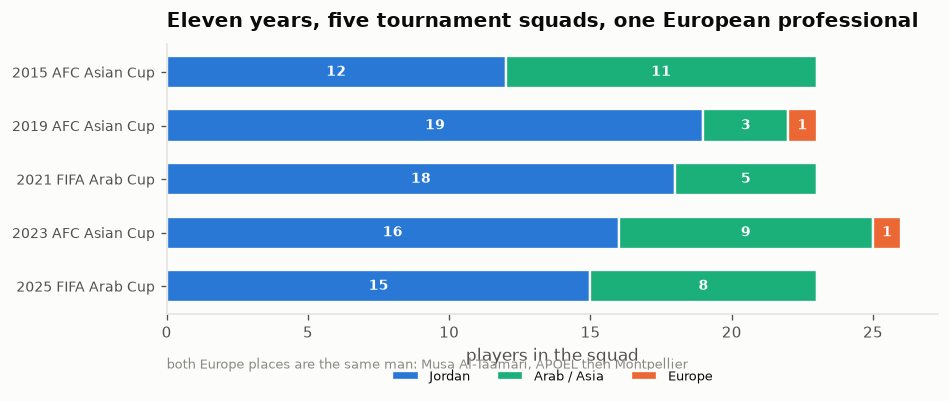

In [6]:
sp = pd.read_csv(SQUAD / "tournament_squad_places.csv")
sp["label"] = sp.squad.str.replace(" squads", "", regex=False)
ordr = sp.groupby("label").when.min().sort_values().index
t = pd.crosstab(sp.label, sp.region).reindex(ordr)
for c in ("Jordan", "Arab / Asia", "Europe"):
    if c not in t:
        t[c] = 0
t = t[["Jordan", "Arab / Asia", "Europe"]]

fig, ax = plt.subplots(figsize=(7.8, 3.2))
y = np.arange(len(t))[::-1]
left = np.zeros(len(t))
COL = {"Jordan": viz.BLUE, "Arab / Asia": viz.AQUA, "Europe": viz.ORANGE}
for c in t.columns:
    v = t[c].values
    ax.barh(y, v, left=left, height=0.6, color=COL[c], label=c,
            edgecolor=viz.SURFACE, linewidth=1.4)
    for yy, (n_, l0) in enumerate(zip(v, left)):
        if n_:
            ax.annotate(str(int(n_)), (l0 + n_ / 2, y[yy]), ha="center",
                        va="center", fontsize=8.5, color=viz.SURFACE,
                        fontweight="bold")
    left = left + v
ax.set_yticks(y)
ax.set_yticklabels(t.index, fontsize=8.5)
ax.set_xlabel("players in the squad")
ax.set_title("Eleven years, five tournament squads, one European professional")
ax.legend(fontsize=8, ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.30))
ax.annotate("both Europe places are the same man: Musa Al-Taamari, "
            "APOEL then Montpellier", xy=(0, -0.20), xycoords="axes fraction",
            fontsize=8, color=viz.INK_MUTED)
viz.despine(ax)
ax.grid(axis="y", visible=False)
plt.show()

🚨 **Jordan reached an Asian Cup final and a World Cup with a squad roughly
two-thirds home-based and one European professional.** Across five squads
spanning eleven years there has never been a second Europe-based man.

Note the two Arab Cup squads carry **zero** — those tournaments fall outside the
FIFA international window, so a Europe-based player is not released. That is
worth knowing before reading the counts as a trend.

**This is the largest untested avenue in the project, and it is untested in a
specific way:** the sample is n = 1, so nothing here can say what sending players
to stronger leagues would do. What can be said is that the improvement measured
in notebooks 02–04 happened **without** the route most improving nations take,
and that the one player who did take it is the same man whose scoring rate
doubled (0.27 → 0.53 per 90).

Two cautions before anyone treats that as a plan:

- **This is five tournament squads, not a career average.** Friendly call-ups are
  invisible and a transfer between tournaments cannot be seen.
- The **CIES Football Observatory** measures squad stability as the share of
  players recruited within a year and puts champion clubs near 25%; **van Vugt et
  al.** find an inverted-U between stability and performance. Moving players
  abroad *reduces* availability and continuity — the two things notebook 03 found
  most clearly went up. The trade-off is real and this data cannot price it.

## 4. What has never been tested

### 4.1 There is no placebo in the squad layer

The project plan calls for the same pipeline on three or four comparable AFC
nations. **Notebook 02 does it for strength** — Iraq, Syria, UAE, and only
Jordan's rise clears zero. **Notebooks 03 and 04 do nothing of the kind.** Every
measure there is Jordan against its own past, so anything really about
international football in the 2020s — squads settling, scoring narrowing, late
goals rising — would look identical.

**This is the largest hole in the analysis**, and the split-date sweep cannot
fill it: that check moves the *date*, not the *team*.

Cost: roughly 600 match reports, mostly uncached. A cheap partial version would
take only the level-at-75 finding, which needs goal minutes and nothing else.

### 4.2 How much would it take? A power calculation

Before spending that, it is worth knowing what any of these comparisons can
resolve at all — because notebook 02's calibration already showed that Jordan's
own 143 matches could not resolve a rise the pooled model puts at +0.717.

**Plotted, left:** the smallest difference in mean result-above-expectation that
a two-era comparison could distinguish from zero, as a function of matches per
era — computed by resampling six-month blocks from Jordan's own record under a
null. **Right:** the same axis converted into calendar time at Jordan's rate of
about 15 matches a year, with the effects this project actually measured marked
for scale.

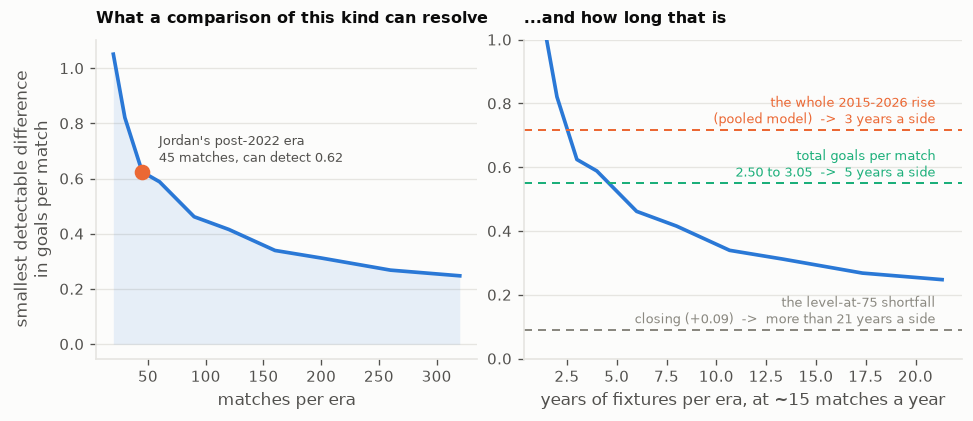

In [7]:
# Minimum detectable effect: build two pseudo-eras of n matches each by
# resampling six-month blocks from the real record (so within-window dependence
# is preserved), and read off how large a difference would have to be to sit
# outside the null's 95% interval.
pool = [d.gd_above_expected.values for _, d in mt.groupby("blk")]
BLOCK = int(np.mean([len(b) for b in pool]))
NS = np.array([20, 30, 45, 60, 90, 120, 160, 200, 260, 320])
mde = []
for n in NS:
    nb_blocks = max(1, int(round(n / BLOCK)))
    diffs = []
    for _ in range(1500):
        a = np.concatenate([pool[i] for i in rng.integers(0, len(pool), nb_blocks)])
        b = np.concatenate([pool[i] for i in rng.integers(0, len(pool), nb_blocks)])
        diffs.append(a.mean() - b.mean())
    mde.append(np.percentile(np.abs(diffs), 95))
mde = np.array(mde)

fig, axes = plt.subplots(1, 2, figsize=(8.0, 3.4),
                         gridspec_kw={"width_ratios": [1, 1.15]})
a = axes[0]
a.plot(NS, mde, color=viz.BLUE, lw=2.2)
a.fill_between(NS, 0, mde, color=viz.BLUE, alpha=0.10, lw=0)
N_POST = int((mt.era == "post").sum())
m_now = np.interp(N_POST, NS, mde)
a.scatter([N_POST], [m_now], color=viz.ORANGE, s=70, zorder=3)
a.annotate(f"Jordan's post-2022 era" + chr(10) + f"{N_POST} matches, "
           f"can detect {m_now:.2f}", xy=(N_POST, m_now), xytext=(10, 6),
           textcoords="offset points", fontsize=8, color=viz.INK_2)
a.set_xlabel("matches per era")
a.set_ylabel("smallest detectable difference" + chr(10) + "in goals per match")
a.set_title("What a comparison of this kind can resolve", fontsize=9.5)
viz.despine(a)

b = axes[1]
YEARS = NS / 15.0
b.plot(YEARS, mde, color=viz.BLUE, lw=2.2)
EFFECTS = [("the whole 2015-2026 rise" + chr(10) + "(pooled model)", 0.717,
            viz.ORANGE),
           ("total goals per match" + chr(10) + "2.50 to 3.05", 0.55, viz.AQUA),
           ("the level-at-75 shortfall" + chr(10) + "closing (+0.09)", 0.09,
            viz.INK_MUTED)]
for lab, v, col in EFFECTS:
    b.axhline(v, color=col, lw=1.2, ls=(0, (4, 3)))
    # np.interp clamps at the ends, so an effect smaller than anything the
    # curve reaches would silently read as the last x value rather than "more"
    need = np.interp(v, mde[::-1], YEARS[::-1])
    txt = (f"{lab}  ->  more than {YEARS[-1]:.0f} years a side" if v < mde.min()
           else f"{lab}  ->  {need:.0f} years a side")
    b.annotate(txt, xy=(YEARS[-1], v), xytext=(-4, 4), ha="right",
               textcoords="offset points", fontsize=7.5, color=col)
b.set_xlabel("years of fixtures per era, at ~15 matches a year")
b.set_ylim(0, 1.0)
b.set_title("...and how long that is", fontsize=9.5)
viz.despine(b)
plt.show()

🚨 **This is the constraint the whole project runs into.** With 45 matches in the
post-2022 era, a two-era comparison can only resolve differences of about **0.6
goals a match** — which is why the rise itself needed a model pooling 49,000 matches
(notebook 02) and why so much of notebook 04 is nulls with wide intervals.

It also prices the placebo honestly: a peer comparison does not need Jordan to
play more, it needs **more teams**. Four nations of comparable record would
roughly halve the detectable effect for anything pooled across them, which is
exactly the argument for spending the 600 match reports rather than waiting a
decade.

### 4.3 Three planned squad measures were never built

XI age, debuts per window, and squad turnover as a formal measure with an
interval. **The data is already on disk.** Debuts look like they would say
something — **14 in 2021, then 1 and 1** — but those years hold 21, 6 and 5
covered matches, so per match it is 0.67 → 0.17 → 0.20. Smaller than the counts
suggest, and exactly why it needs building with an interval rather than quoting.

### 4.4 Smaller items, recorded so they are not rediscovered

- **Minutes at risk stop at 90** while stoppage is always played. Notebook 04's
  spike survives eight added minutes; the clock is still wrong.
- **Six Arab Cup names** are unconfirmed transliteration matches, deliberately
  unmerged. Confirming them by hand adds ten matches to the appearance measures.
- **Nineteen matches have no event feed** — 14 friendlies and 5 competitive.
  Coverage is balanced across eras at 89%, so this is noise rather than bias, but
  it caps the post side near 40 matches, which is why the state-crossed intervals
  are as wide as they are.
- **WAFF, the Palestine International Championship, the King's Cup and the Jordan
  International Tournament** — 14 competitive matches, several rotation-heavy,
  tracked by nobody. Squad turnover is biased slightly downward because of them.

## 5. What cannot be known from this data

Stated plainly rather than worked around, because each of these is a question
somebody will ask of the conclusions.

| question | why it is unanswerable here |
|---|---|
| **Did Jordan create more chances?** | No shot data across the boundary — 1.4% of pre-2022 appearance rows against 20% after. Not a gap that more sourcing closes. |
| **Why does Jordan concede from level scorelines?** | Needs shot locations or possession. Possession exists for 27 of 174 matches, concentrated after 2023, so filling it in would put the coverage boundary on the treatment date. |
| **Was it the manager, the squad, or the schedule?** | All three move together across mid-2022. No design available separates them. |
| **Is the 2022 improvement causal?** | No. This is a coincidence with uncertainty, and the notebooks say so throughout. |

## The priority list

Ranked by how much each would change what the other four notebooks say.

| | what | why it matters | cost |
|---|---|---|---|
| **1** | **The placebo** — the squad pipeline on Iraq, Palestine, Oman, Bahrain | Every measure in notebooks 03–04 is Jordan against its own past. If settling squads and narrowing scoring are just what the 2020s look like, most of the analysis dissolves. | ~600 match reports, mostly uncached |
| **2** | **Confirm the six Arab Cup names** | Adds ten matches to every appearance-based measure, in exactly the rotation-heavy fixtures that are currently missing | a person, an afternoon |
| **3** | **Build XI age, debuts and turnover properly, with intervals** | Three planned measures never built; data already on disk | a day |
| **4** | **Re-centre the late-goal finding on direction in any write-up** | The rate ratio and the points shortfall are both partly the model's mis-specification. The direction is not. | done here; carry it forward |
| **5** | **Watch top-3 goal share** | A rise carried by a narrow group is more fragile than one carried by a broad one. This is the early-warning number. | free, ongoing |

### The one-sentence version

> Jordan got measurably better, in attack, with a narrower and more settled
> group, against opposition that got harder faster than it did — and the clearest
> remaining gap is that from a level scoreline late in a match the goals still go
> the wrong way three times in four.

---

### What this project would need to say something stronger

More teams, not more years. The power calculation in section 4.2 is the whole
argument: at fifteen matches a year, Jordan alone cannot resolve the questions
notebooks 03 and 04 ask. The strength model works because it pools 49,000
matches; the squad layer does not pool anything, and that — not the scraping, not
the parsing — is what limits it.